In [15]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

import gymnasium as gym

In [16]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [17]:
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


___
### **2-3. 예제에 사용할 CartPole 데이터 설명**

- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제이다.
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모른다.
- 환경이 제공하는 관측값
    - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
    - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
    - 막대 각도: 막대가 어느 쪽으로 얼마나 기울어졌는가
    - 막대 각속도: 기울기가 얼마나 빨리 변하는가
- 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓는다. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라 장기적으로 균형을 오래 유지하는 행동이다.
- reset(): 새 시도를 시작
- step(action): 행동 후 (관측, 보상, terminated, truncated, info) 다섯 가지를 반환
    - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
    - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

```
pip install gymnasium
```

In [18]:
probe = gym.make('CartPole-v1')
obs, info = probe.reset(seed=SEED)
print('관측: ', obs, ' | 관측 공간: ', probe.observation_space)
print('행동 공간: ', probe.action_space)
next_obs, reward, terminated, truncated, info = probe.step(0)
print('한 단계 결과: ', reward, terminated, truncated)
probe.close()

관측:  [-0.03210652  0.01399132 -0.00327316 -0.01294995]  | 관측 공간:  Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간:  Discrete(2)
한 단계 결과:  1.0 False False


In [19]:
### 
class ReplayBuffer:
    def __init__(self, capacity=30000):
        self.data = deque(maxlen=capacity)

    def add(self, s, a, r, ns, terminated):
        self.data.append((s, a, r, ns, terminated))

    def sample(self, batch_size):
        batch = random.sample(self.data, batch_size)
        s, a, r, ns, d = zip(*batch)
        return (torch.as_tensor(np.asarray(s),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1),
                torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1),
                torch.as_tensor(np.asarray(ns),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(d,dtype=torch.float32,device=DEVICE).unsqueeze(1))

    def __len__(self):
        return len(self.data)

In [20]:
### 
class QNetWork(nn.Module):
    def __init__(self, obs_dim=4, actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, actions)
        )

    # 순전파
    def forward(self, x):
        return self.net(x)

In [21]:
q_test = QNetWork().to(DEVICE)
q_test

QNetWork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [22]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


In [23]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
    states, actions, rewards, next_states, terminated = buffer.sample(batch_size)

    # online(states)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만든다.
    # gather(...): 신경망이 출력한 여러 행동 점수 중에서 실제로 선택했던 행동의 점수만 추출
    choosen_q = online(states).gather(1, actions)
    with torch.no_grad():
        if double:
            # 행동을 고른 다음 그 행동을 평가
            next_actions = online(next_states).argmax(dim=1, keepdim=True) 
            next_q = target(next_states).gather(1, next_actions) 

        else:
            # 다음 상태의 최대 Q값을 구함
            next_q = target(next_states).max(dim=1, keepdim=True).values
        # TD 목표값
        targets = rewards + gamma * (1 - terminated) * next_q
    loss = nn.functional.smooth_l1_loss(choosen_q, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()
    return float(loss.item())

___
### **2) 예제: DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기**

1. 구현 요구사항
    - CartPole-v1 환경 생성
    - Online Network와 Target Network 생성
    - Adam 옵티마이저, Replay Buffer 초기화
    - 초기에는 무작위 행동을 많이 선택하도록 구현
    - 학습이 진행될수록 ε값을 감소
    - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
    - 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 Replay Buffer에 저장
    - Replay Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
    - 4스탭마다 dqn_update() 실행
    - 500 스탭마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
    - 총 250개 에피소드 학습
    - 에피소드별 누적 보상 저장
    - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력

3. 학습 결과 시각화
    - 에피소드별 누적 보상
    - 최근 20개 에프소드의 이동평균 보상

In [24]:

# 1. 환경 및 네트워크 초기화
env = gym.make("CartPole-v1")

online = QNetWork().to(DEVICE)
target = QNetWork().to(DEVICE)

# 초기 가중치 동기화
target.load_state_dict(online.state_dict())
target.eval()

optimizer = optim.Adam(online.parameters(), lr=0.001)
buffer = ReplayBuffer(capacity=30000)


# 2. 하이퍼파라미터 설정
EPISODES = 250
GAMMA = 0.99

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

total_steps = 0
episode_rewards = []


# 3. 에피소드별 학습
for episode in range(EPISODES):

    state, info = env.reset(seed=SEED + episode)
    episode_reward = 0

    while True:

        # 4. 행동 선택 (Epsilon-Greedy)
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                state_tensor = torch.as_tensor(
                    state, dtype=torch.float32,
                    device=DEVICE
                ).unsqueeze(0)

                q_values = online(state_tensor)
                action = q_values.argmax(dim=1).item()

        # 5. 선택한 행동을 환경에 적용
        next_state, reward, terminated, truncated, info = env.step(action)

        # 6. 경험 저장
        buffer.add(state, action, reward, next_state, terminated)

        episode_reward += reward
        total_steps += 1

        # 7. DQN 학습
        if len(buffer) >= 1000 and total_steps % 4 == 0:
            loss = dqn_update(
                online, target, buffer, optimizer,
                batch_size=64, gamma=GAMMA
            )

        # 8. Target Network 동기화
        if total_steps % 500 == 0:
            target.load_state_dict(online.state_dict())

        state = next_state

        if terminated or truncated:
            break

    # 9. Epsilon 감소 및 보상 기록
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    episode_rewards.append(episode_reward)

    # 10. 50개 에피소드마다 출력
    if (episode + 1) % 50 == 0:
        avg_reward = np.mean(episode_rewards[-20:])
        print(
            f"Episode {episode + 1}/{EPISODES} | "
            f"최근 20개 평균 보상: {avg_reward:.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

env.close()


Episode 50/250 | 최근 20개 평균 보상: 22.20 | Epsilon: 0.778
Episode 100/250 | 최근 20개 평균 보상: 18.00 | Epsilon: 0.606
Episode 150/250 | 최근 20개 평균 보상: 55.60 | Epsilon: 0.471
Episode 200/250 | 최근 20개 평균 보상: 146.85 | Epsilon: 0.367
Episode 250/250 | 최근 20개 평균 보상: 191.00 | Epsilon: 0.286


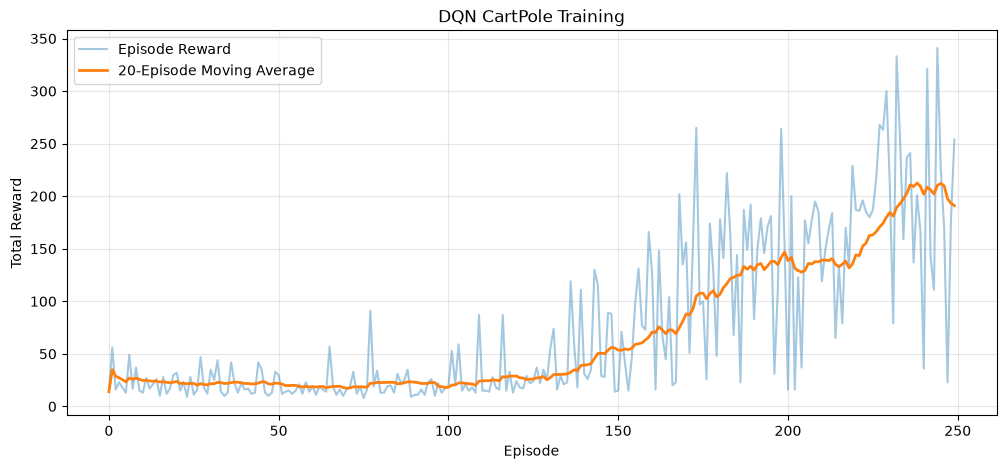

In [25]:

# 최근 20개 에피소드 이동평균
moving_avg = [
    np.mean(episode_rewards[max(0, i - 19):i + 1])
    for i in range(len(episode_rewards))
]

plt.figure(figsize=(12, 5))

plt.plot(
    episode_rewards,
    label="Episode Reward",
    alpha=0.4
)

plt.plot(
    moving_avg,
    label="20-Episode Moving Average",
    linewidth=2
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("DQN CartPole Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
